Libraries imported successfully!


Saving Restaurant_Reviews.tsv.txt to Restaurant_Reviews.tsv (2).txt

Dataset loaded successfully!
Dataset shape: (1000, 2)


,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1



Column names:
Index(['Review', 'Liked'], dtype='object')

Missing values:
Review    0
Liked     0
dtype: int64

Sentiment distribution:
Liked
1    500
0    500
Name: count, dtype: int64

Converted labels:


,Review,Sentiment
0,Wow... Loved this place.,Positive
1,Crust is not good.,Negative
2,Not tasty and the texture was just nasty.,Negative
3,Stopped by during the late May bank holiday of...,Positive
4,The selection on the menu was great and so wer...,Positive


...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BERT model loaded successfully!

BERT predictions:


,Review,Sentiment,Predicted_Sentiment,Confidence_Percentage
0,Wow... Loved this place.,Positive,LABEL_1,99.96
1,Crust is not good.,Negative,LABEL_0,99.86
2,Not tasty and the texture was just nasty.,Negative,LABEL_0,99.90
3,Stopped by during the late May bank holiday of...,Positive,LABEL_1,99.93
4,The selection on the menu was great and so wer...,Positive,LABEL_1,99.94
5,Now I am getting angry and I want my damn pho.,Negative,LABEL_0,99.72
6,Honeslty it didn't taste THAT fresh.),Negative,LABEL_0,99.50
7,The potatoes were like rubber and you could te...,Negative,LABEL_0,99.64
8,The fries were great too.,Positive,LABEL_1,99.92
9,A great touch.,Positive,LABEL_1,99.98



BERT Accuracy on 100 reviews: 0.0 %


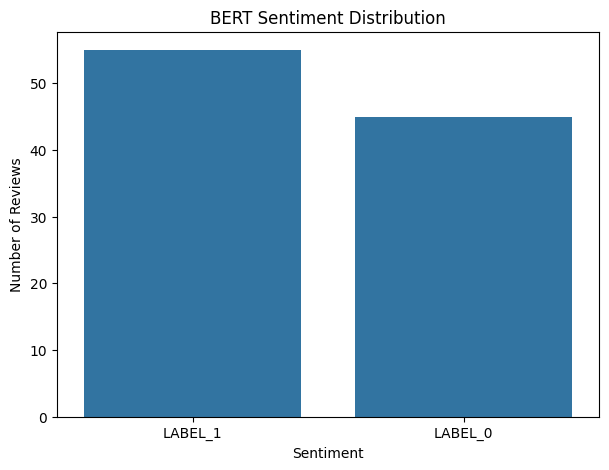

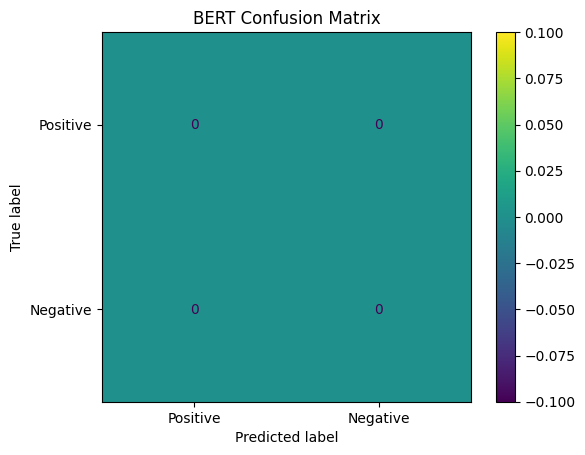


ENTER YOUR OWN REVIEW
Enter your review: The phone camera is amazing and the screen is beautiful, but the battery drains very quickly.

Your Review:
The phone camera is amazing and the screen is beautiful, but the battery drains very quickly.

BERT Prediction:
Sentiment: LABEL_0
Confidence: 98.68%

ASPECT BASED SENTIMENT ANALYSIS


config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

spm.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/18.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

ABSA model loaded successfully!

Enter the aspects you want to analyze.
Example: food, service, price
Enter aspects separated by commas: camera, screen, battery

Aspect-Based Sentiment Results:


,Aspect,Sentiment,Confidence
0,camera,Positive,99.72
1,screen,Positive,99.68
2,battery,Negative,99.48


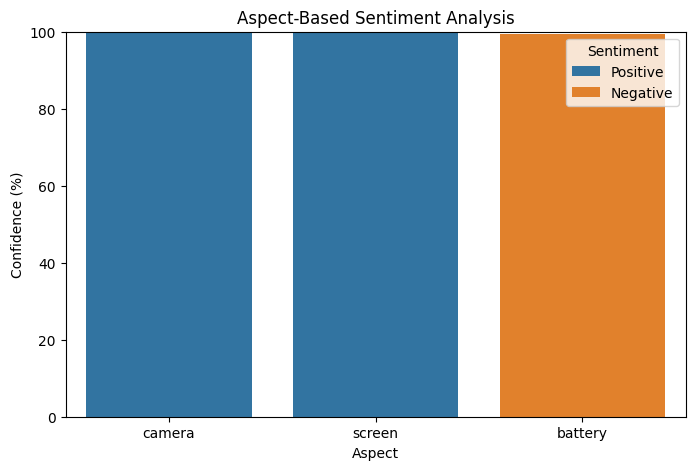


FINAL RESULT

Overall Sentiment:
LABEL_0
Overall Confidence: 98.68%

Aspect-Based Sentiment:


,Aspect,Sentiment,Confidence
0,camera,Positive,99.72
1,screen,Positive,99.68
2,battery,Negative,99.48



Project completed successfully!


In [ ]:
# ============================================================
# BERT SENTIMENT ANALYSIS + YOUR OWN REVIEW
# Restaurant Reviews Dataset
# ============================================================

# Install required libraries
!pip install -q transformers torch pandas matplotlib seaborn sentencepiece

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline

print("Libraries imported successfully!")

# ------------------------------------------------------------
# 2. UPLOAD DATASET
# ------------------------------------------------------------

from google.colab import files

uploaded = files.upload()

# Read the uploaded TSV file
df = pd.read_csv("Restaurant_Reviews.tsv (1).txt", sep="\t")
print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

# ------------------------------------------------------------
# 3. CHECK DATASET
# ------------------------------------------------------------

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["Liked"].value_counts())

# ------------------------------------------------------------
# 4. CONVERT LABELS
# ------------------------------------------------------------

df["Sentiment"] = df["Liked"].map({
    0: "Negative",
    1: "Positive"
})

print("\nConverted labels:")
display(df[["Review", "Sentiment"]].head())

# ------------------------------------------------------------
# 5. LOAD BERT MODEL
# ------------------------------------------------------------

device = 0 if torch.cuda.is_available() else -1

print("\nDevice:",
      "GPU" if device == 0 else "CPU")

model_name = "textattack/bert-base-uncased-SST-2"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=model_name,
    tokenizer=model_name,
    device=device
)

print("BERT model loaded successfully!")

# ------------------------------------------------------------
# 6. TEST BERT ON DATASET
# ------------------------------------------------------------

# Use 100 reviews first so the notebook runs faster
sample_df = df.head(100).copy()

predictions = []

for review in sample_df["Review"]:
    result = sentiment_pipeline(str(review))[0]

    predictions.append({
        "Predicted_Sentiment": result["label"],
        "Confidence": result["score"]
    })

prediction_df = pd.DataFrame(predictions)

sample_df = pd.concat(
    [
        sample_df.reset_index(drop=True),
        prediction_df
    ],
    axis=1
)

sample_df["Confidence_Percentage"] = (
    sample_df["Confidence"] * 100
).round(2)

print("\nBERT predictions:")
display(
    sample_df[
        [
            "Review",
            "Sentiment",
            "Predicted_Sentiment",
            "Confidence_Percentage"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 7. CALCULATE ACCURACY
# ------------------------------------------------------------

correct = (
    sample_df["Sentiment"].str.upper()
    ==
    sample_df["Predicted_Sentiment"].str.upper()
)

accuracy = correct.mean() * 100

print("\nBERT Accuracy on 100 reviews:",
      round(accuracy, 2), "%")

# ------------------------------------------------------------
# 8. SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    data=sample_df,
    x="Predicted_Sentiment"
)

plt.title("BERT Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

true_labels = sample_df["Sentiment"].str.upper()
predicted_labels = sample_df["Predicted_Sentiment"].str.upper()

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=["POSITIVE", "NEGATIVE"]
)

display_obj = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Positive", "Negative"]
)

display_obj.plot()

plt.title("BERT Confusion Matrix")
plt.show()

# ------------------------------------------------------------
# 10. ENTER YOUR OWN REVIEW
# ------------------------------------------------------------

print("\n========================================")
print("ENTER YOUR OWN REVIEW")
print("========================================")

my_review = input("Enter your review: ")

my_result = sentiment_pipeline(my_review)[0]

print("\nYour Review:")
print(my_review)

print("\nBERT Prediction:")
print("Sentiment:", my_result["label"])
print("Confidence:", f"{my_result['score']:.2%}")

# ------------------------------------------------------------
# 11. ABSA MODEL
# ------------------------------------------------------------

print("\n========================================")
print("ASPECT BASED SENTIMENT ANALYSIS")
print("========================================")

absa_model = "yangheng/deberta-v3-base-absa-v1.1"

absa_pipeline = pipeline(
    "text-classification",
    model=absa_model,
    tokenizer=absa_model,
    device=device
)

print("ABSA model loaded successfully!")

# ------------------------------------------------------------
# 12. ENTER ASPECTS
# ------------------------------------------------------------

print("\nEnter the aspects you want to analyze.")
print("Example: food, service, price")

aspect_input = input("Enter aspects separated by commas: ")

aspects = [
    aspect.strip()
    for aspect in aspect_input.split(",")
    if aspect.strip()
]

# ------------------------------------------------------------
# 13. RUN ABSA
# ------------------------------------------------------------

absa_results = []

for aspect in aspects:

    result = absa_pipeline(
        my_review,
        text_pair=aspect
    )[0]

    absa_results.append({
        "Aspect": aspect,
        "Sentiment": result["label"],
        "Confidence": round(result["score"] * 100, 2)
    })

absa_df = pd.DataFrame(absa_results)

print("\nAspect-Based Sentiment Results:")

display(absa_df)

# ------------------------------------------------------------
# 14. ABSA GRAPH
# ------------------------------------------------------------

if len(absa_df) > 0:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=absa_df,
        x="Aspect",
        y="Confidence",
        hue="Sentiment"
    )

    plt.title("Aspect-Based Sentiment Analysis")
    plt.xlabel("Aspect")
    plt.ylabel("Confidence (%)")

    plt.ylim(0, 100)

    plt.show()

# ------------------------------------------------------------
# 15. FINAL RESULT
# ------------------------------------------------------------

print("\n========================================")
print("FINAL RESULT")
print("========================================")

print("\nOverall Sentiment:")
print(my_result["label"])

print("Overall Confidence:",
      f"{my_result['score']:.2%}")

print("\nAspect-Based Sentiment:")

display(absa_df)

print("\nProject completed successfully!")